In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from ipynb.fs.full.preprocessing import process_the_data, read_the_data

<h3> Looking at the steps calculated by DeltabotController

In [3]:
mesh0045_27Oct = pd.read_csv("processed_data/27Oct_0045_mesh.csv")

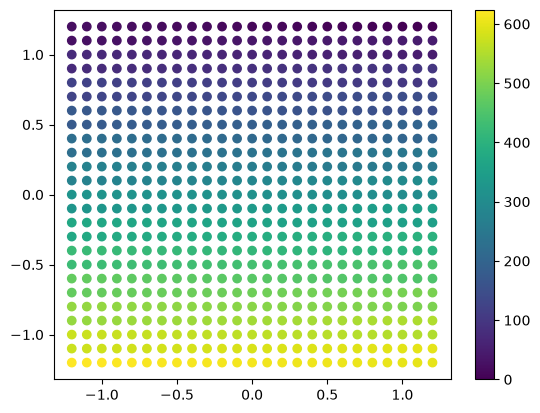

In [4]:
plt.scatter(mesh0045_27Oct["x"], mesh0045_27Oct["y"], c=mesh0045_27Oct["point"]) # the input and the goal
plt.colorbar()

In [5]:
mesh0045_27Oct['sum_motors'] = mesh0045_27Oct["s0"] + mesh0045_27Oct["s1"] + mesh0045_27Oct["s2"]
mesh0045_27Oct['sum_motors']

0      0.0
1      0.0
2      0.0
3      0.0
4      0.0
      ... 
620    0.0
621    0.0
622    0.0
623    0.0
624    0.0
Name: sum_motors, Length: 625, dtype: float64

Text(0.5, 0.98, 'Calculated steps in order')

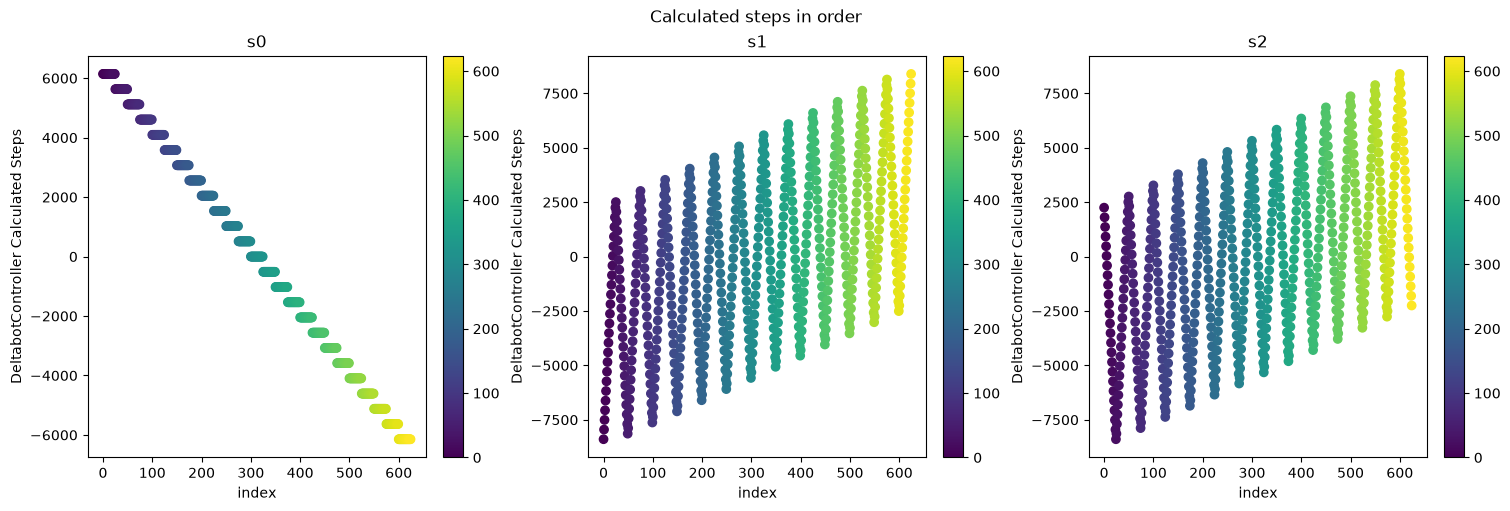

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)
for i, motor in enumerate(["s0", "s1", "s2"]):
    im = axs[i].scatter(mesh0045_27Oct[motor].index, mesh0045_27Oct[motor], c=mesh0045_27Oct.index)
    axs[i].set_xlabel("index")
    axs[i].set_ylabel("DeltabotController Calculated Steps")
    axs[i].set_title(motor)
    fig.colorbar(im, ax=axs[i])
fig.suptitle("Calculated steps in order")

We can see that the snaking behaviour of the steps

In [10]:
# algorithm_steps
print("Calculated Motor Values Max/Min")
print(max(mesh0045_27Oct["s0"]))
print(max(mesh0045_27Oct["s1"]))
print(max(mesh0045_27Oct["s2"]))
print(min(mesh0045_27Oct["s0"]))
print(min(mesh0045_27Oct["s1"]))
print(min(mesh0045_27Oct["s2"]))

Calculated Motor Values Max/Min
6144.0
8393.0
8393.0
-6144.0
-8393.0
-8393.0


<h1> Try again with snaking x and y data

In [7]:
#gave those x and y values to the 16Oct MLP 
#output
pred_snake_steps = pd.read_csv("predictions/16Oct_MLP_Pred_snake_mesh.csv", names=["s0", "s1", "s2"])
display(pred_snake_steps.head())
print("Predicted motor values Max/Min")
print(max(pred_snake_steps["s0"]))
print(max(pred_snake_steps["s1"]))
print(max(pred_snake_steps["s2"]))
print(min(pred_snake_steps["s0"]))
print(min(pred_snake_steps["s1"]))
print(min(pred_snake_steps["s2"]))

,s0,s1,s2
0,3784.347412,-5773.159668,1990.905518
1,3797.737549,-5510.299805,1715.915161
2,3810.368408,-5245.808594,1440.044556
3,3817.305908,-4976.723145,1165.238770
4,3822.103760,-4708.941406,893.872314


Predicted motor values Max/Min
3853.146240234375
7026.98046875
6969.173828125
-5522.0439453125
-5773.15966796875
-4507.67138671875


In [26]:
pred_snake_steps['sum_motors'] = pred_snake_steps["s0"] + pred_snake_steps["s1"] + pred_snake_steps["s2"]
# display(pred_snake_steps['sum_motors'])
print(max(pred_snake_steps["sum_motors"]))
print(min(pred_snake_steps["sum_motors"]))

print(pred_snake_steps.shape[0])

#adjust motor values so they always sum to 0

pred_snake_steps["s0_adj"] = pred_snake_steps["s0"] - (pred_snake_steps["sum_motors"]/3)
pred_snake_steps["s1_adj"] = pred_snake_steps["s1"] - (pred_snake_steps["sum_motors"]/3)
pred_snake_steps["s2_adj"] = pred_snake_steps["s2"] - (pred_snake_steps["sum_motors"]/3)

pred_snake_steps['sum_motors_adj'] = pred_snake_steps["s0_adj"] + pred_snake_steps["s1_adj"] + pred_snake_steps["s2_adj"]
# display(pred_snake_steps['sum_motors'])
print(max(pred_snake_steps["sum_motors_adj"]))
print(min(pred_snake_steps["sum_motors_adj"]))


15.833740234375
-14.437744140625
625
9.094947017729282e-13
-9.094947017729282e-13


Text(0.5, 0.98, 'Predictions from Standard MLP Snake Scan')

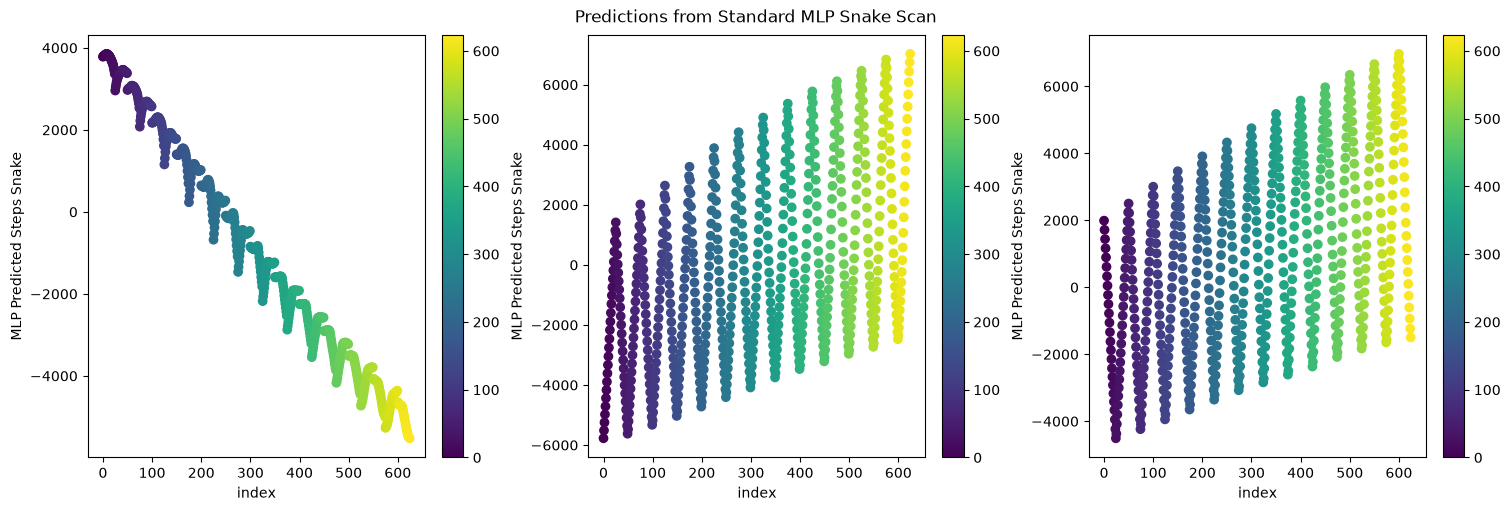

In [74]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)
for i, motor in enumerate(["s0", "s1", "s2"]):
    im = axs[i].scatter(pred_snake_steps[motor].index, pred_snake_steps[motor], c=pred_snake_steps.index)
    axs[i].set_xlabel("index")
    axs[i].set_ylabel("MLP Predicted Steps Snake")
    fig.colorbar(im, ax=axs[i]) 
fig.suptitle("Predictions from Standard MLP Snake Scan")

Text(0.5, 0.98, 'Predictions from Standard MLP Snake Scan - motor values adjusted to sum to 0')

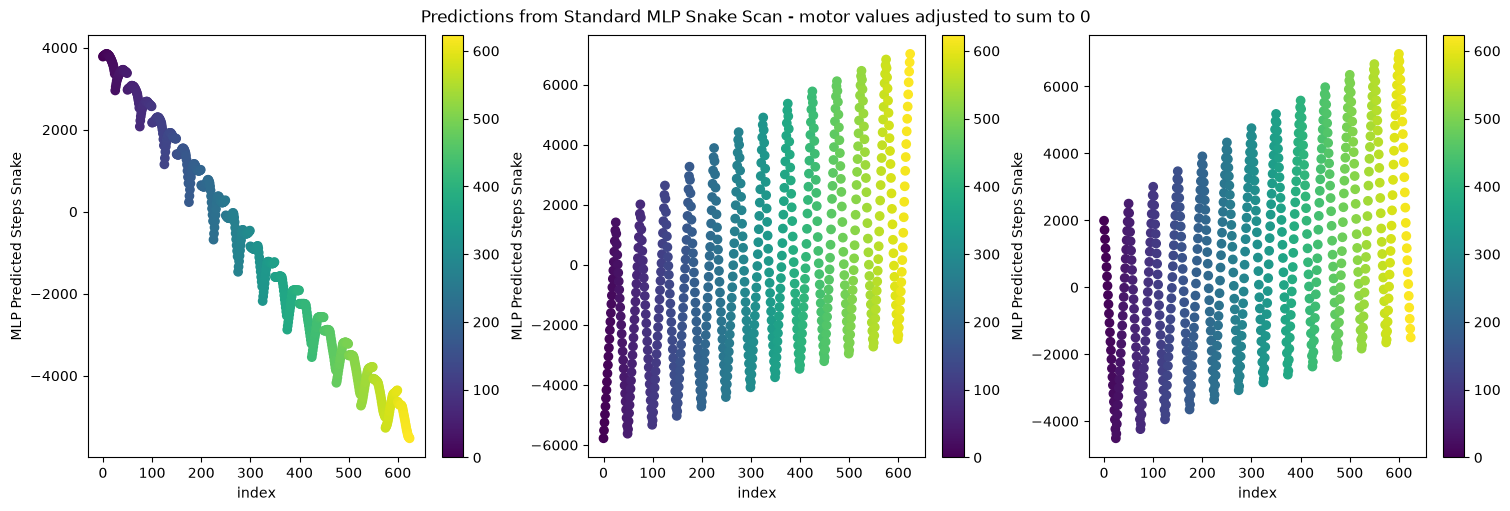

In [75]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)
for i, motor in enumerate(["s0_adj", "s1_adj", "s2_adj"]):
    im = axs[i].scatter(pred_snake_steps[motor].index, pred_snake_steps[motor], c=pred_snake_steps.index)
    axs[i].set_xlabel("index")
    axs[i].set_ylabel("MLP Predicted Steps Snake")
    fig.colorbar(im, ax=axs[i])
fig.suptitle("Predictions from Standard MLP Snake Scan - motor values adjusted to sum to 0")

<h2> Comparing the 2 datasets

Text(0.5, 0.98, 'DeltabotController Motor values vs Standard MLP Predictions for snake scan')

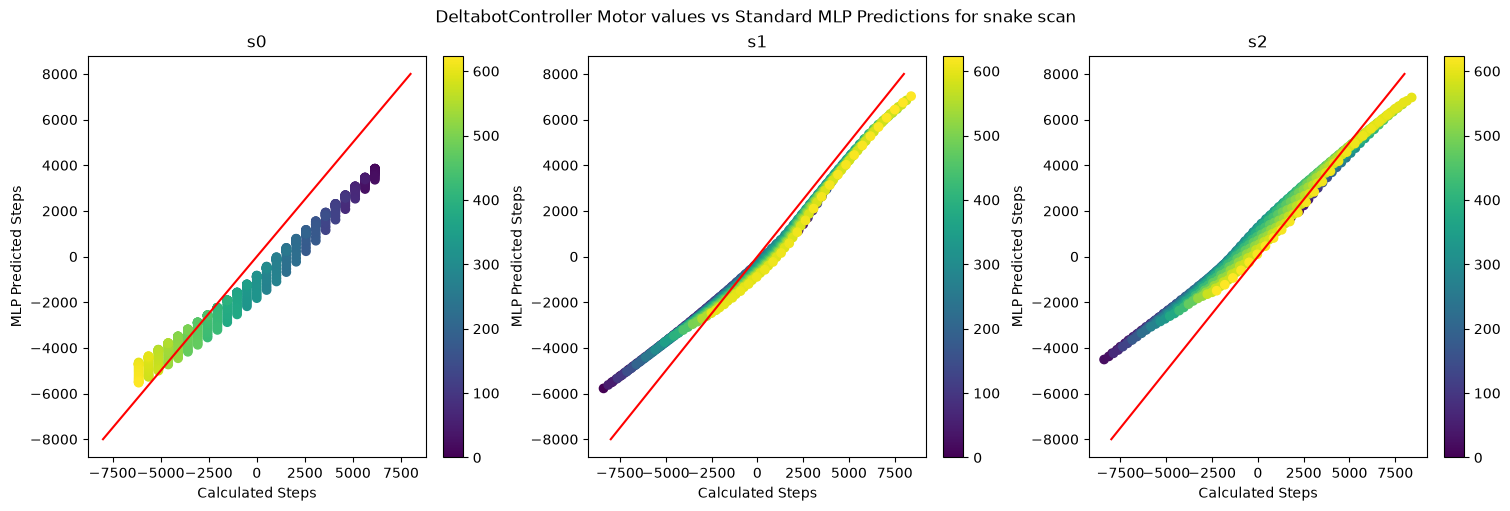

In [30]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)
for i, motor in enumerate(["s0", "s1", "s2"]):
    im = axs[i].scatter(mesh0045_27Oct[motor], pred_snake_steps[motor], c=mesh0045_27Oct["point"])
    axs[i].set_xlabel("Calculated Steps")
    axs[i].set_ylabel("MLP Predicted Steps")
    fig.colorbar(im, ax=axs[i])  
    axs[i].set_title(motor)
    lims = [-8000, 8000]
    # axs[i].set_xlim(lims)
    # axs[i].set_ylim(lims)
    _ = axs[i].plot(lims, lims, color="red")

fig.suptitle("DeltabotController Motor values vs Standard MLP Predictions for snake scan")

Text(0.5, 0.98, 'DeltabotController Motor values vs Standard MLP Predictions for snake scan - values adjusted to sum to 0')

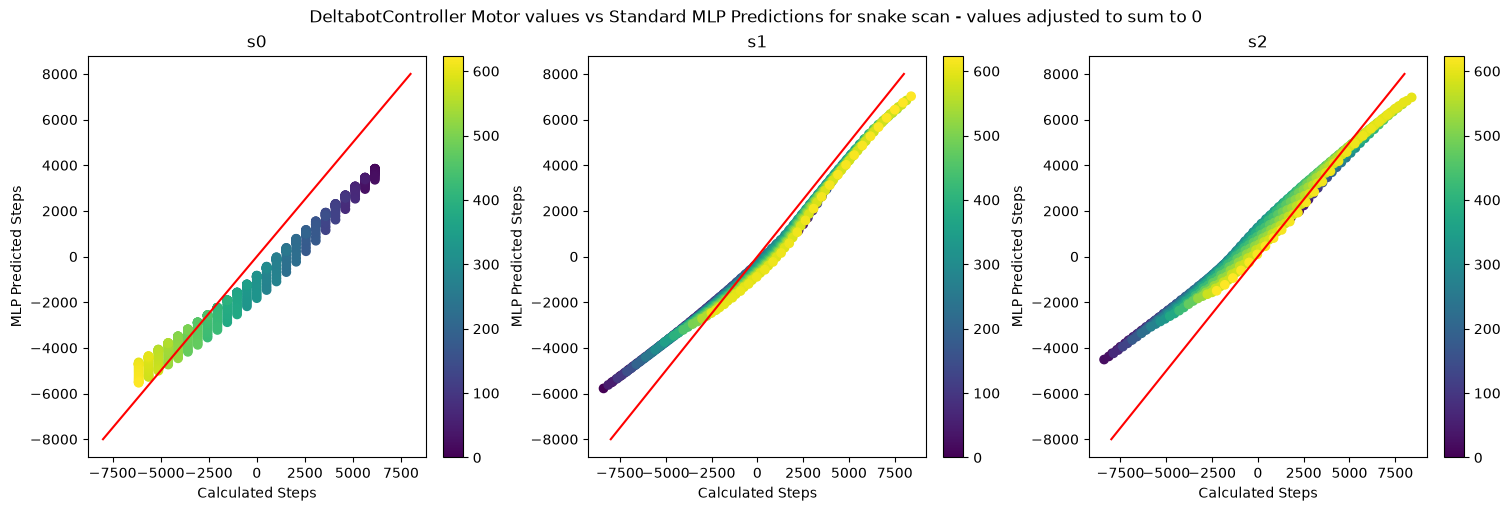

In [32]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)
for i, motor in enumerate(["s0", "s1", "s2"]):
    im = axs[i].scatter(mesh0045_27Oct[motor], pred_snake_steps[f"{motor}_adj"], c=mesh0045_27Oct["point"])
    axs[i].set_xlabel("Calculated Steps")
    axs[i].set_ylabel("MLP Predicted Steps")
    fig.colorbar(im, ax=axs[i])  
    axs[i].set_title(motor)
    lims = [-8000, 8000]
    # axs[i].set_xlim(lims)
    # axs[i].set_ylim(lims)
    _ = axs[i].plot(lims, lims, color="red")

fig.suptitle("DeltabotController Motor values vs Standard MLP Predictions for snake scan - values adjusted to sum to 0")

In [77]:
pred_snake_steps[["s0_adj", "s1_adj", "s2_adj"]].astype("int32").to_csv("predictions/adjusted/16Oct_MLP_snake.csv", index=False)

In [44]:
data = pd.read_csv("predictions/adjusted/16Oct_MLP_snake.csv")
points = list(data.itertuples(name=None, index=False))
print(points)

[(3783, -5773, 1990), (3796, -5511, 1714), (3808, -5247, 1438), (3815, -4978, 1163), (3819, -4711, 891), (3830, -4439, 609), (3842, -4168, 325), (3849, -3895, 45), (3846, -3614, -231), (3840, -3334, -505), (3833, -3049, -784), (3820, -2761, -1058), (3810, -2467, -1342), (3797, -2173, -1624), (3774, -1893, -1880), (3751, -1601, -2149), (3727, -1303, -2423), (3700, -1020, -2680), (3672, -748, -2923), (3639, -465, -3173), (3605, -186, -3418), (3567, 100, -3668), (3507, 441, -3949), (3440, 791, -4232), (3364, 1145, -4509), (2958, 1414, -4372), (3046, 1037, -4083), (3118, 680, -3799), (3185, 330, -3516), (3234, 15, -3250), (3269, -263, -3005), (3301, -547, -2753), (3330, -827, -2503), (3357, -1114, -2242), (3379, -1412, -1967), (3401, -1712, -1689), (3423, -1996, -1427), (3433, -2293, -1140), (3442, -2592, -849), (3451, -2881, -569), (3457, -3171, -286), (3462, -3451, -11), (3454, -3734, 279), (3441, -4011, 570), (3429, -4282, 853), (3423, -4551, 1127), (3414, -4821, 1407), (3404, -5092, 16

In [ ]:
# list(pred_snake_steps.itertuples(index=False, name=None))

<h1>Output from Scan using predicted motor values

In [71]:
path = "scripts/scans/MLP"
scan = "0006_MLP_16Oct"

x_conversion = 0.1/11
y_conversion = x_conversion

start_cx = 314 #px #scan 94
start_cy = 264 #px #scan 94

scan_MLP = process_the_data(scan, path, x_conversion, y_conversion, start_cx, start_cy)
scan_MLP.name = "scan_MLP"

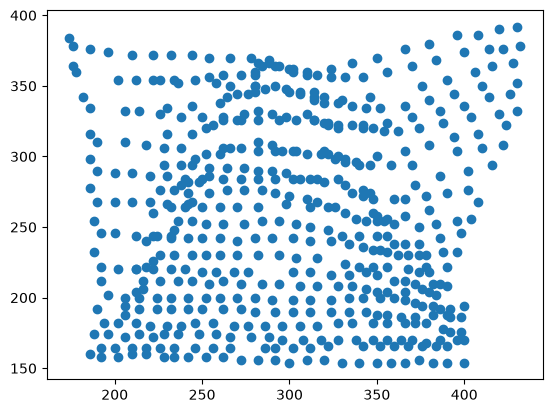

In [72]:
plt.scatter(scan_MLP["cx"], scan_MLP["cy"])

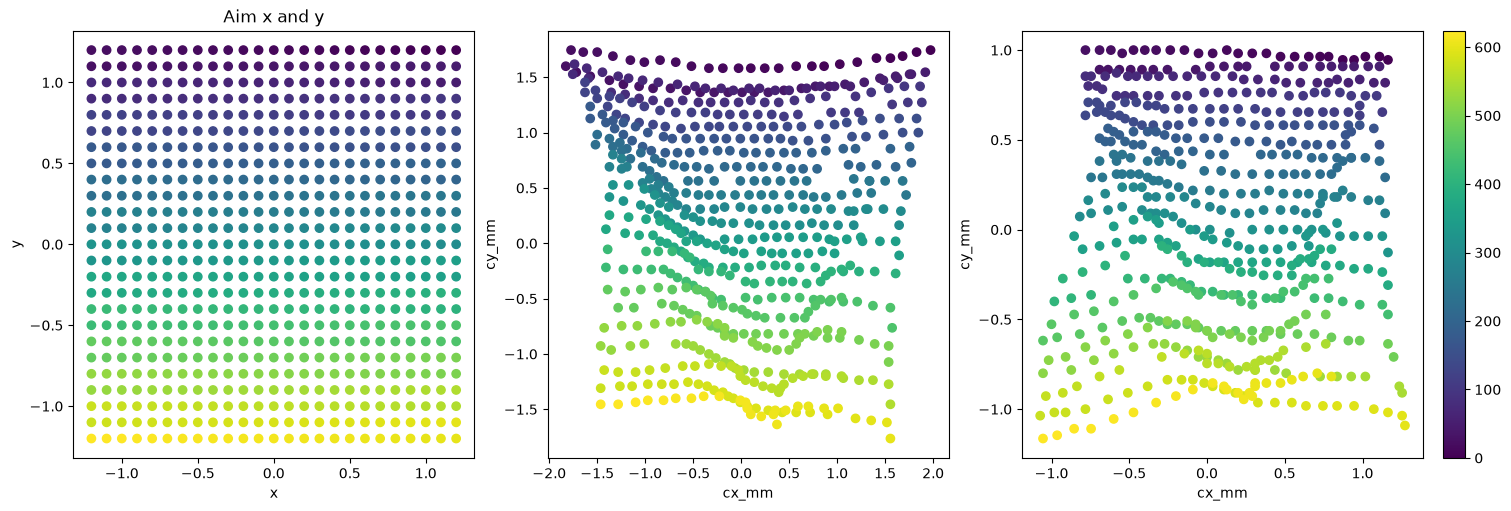

In [73]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)

im = axs[0].scatter(mesh0045_27Oct["x"], mesh0045_27Oct["y"], c=mesh0045_27Oct["point"])
axs[0].set_xlabel("x")
axs[0].set_ylabel("y")
axs[0].set_title("Aim x and y")

i = 1
for scan in mesh0045_27Oct, scan_MLP:
    subplot = axs[i]
    subplot.scatter(scan["cx_mm"], scan["cy_mm"], c=scan["point"])
    subplot.set_xlabel("cx_mm")
    subplot.set_ylabel("cy_mm")
    # subplot.set_xlim(-1.2, 1.2)
    # subplot.set_ylim(-1.2,1.2)

    # fig.colorbar(im, ax=axs[i])  
    # subplot.set_title(scan.name)
    i = i+1

fig.colorbar(im, ax=axs[2])  